# QuantaSound · Personalized cancellation
## Choose sounds → simulate anti-noise → listen → measure → save preferences

**New:** sound-selection controls, paired playback, performance measurements and persistent profiles.

This experiment mixes real speech, engine and keyboard recordings. Separate source tracks provide **ideal known references**; we are not separating sounds from one microphone mixture. FxLMS generates a control signal, propagates it through the simulated speaker-to-ear path and adds the opposing sound at the ear. This is an offline simulation, not physical headphone ANC.

Use Python 3.12, install `requirements.txt`, open this notebook in JupyterLab and Run All. The controls need a running Python kernel; GitHub and exported HTML only show the saved examples.

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd()
if not (root/'demo2').exists():
    root = root.parent
assert (root/'demo2').exists(), 'Open from the repo root or demo2 folder'
sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Audio, Image
from demo2.simulation import load_sources, simulate
from demo2.presentation import show_result, metric_rows
%matplotlib inline

## Listen here first: audible hum demonstration
**There is no siren in this mixture.** The original engine recording is dominated by very low bass (around 37 Hz), which may be weak on laptop speakers. In the recorded-engine result, about 93% of the before-minus-after signal energy is below 100 Hz; the whole mixed audio changes by only about 1.87 dB over the full recording, even though the selected-target residual metric is larger.

This additional listening example deliberately uses a **synthetic 200 Hz hum with harmonics**, plus speech and a quieter keyboard track. It is not the original engine recording and is an easier teaching scenario. The original recording/results remain below. Its levels are documented separately, not substituted into the original benchmark.

First identify the individual sources below. Solo players are independently scaled only for identification. Then compare the full mixture before/after using the single quick A/B player, which preserves exactly the same gain for both halves.

Sources present: engine/hum, keyboard and speech. There is NO siren in this mixture.
Each solo below is independently scaled for identification, NOT for judging cancellation or mixture balance.
engine


keyboard


speech


Online FxLMS, low-pass secondary path
Paired adaptive reruns


Measurement,Result,Meaning
Total residual-noise reduction,13.14 dB,Higher is better; unselected noise is still present
Selected-target residual reduction,15.90 dB,Includes added artifacts; can be negative
Speech-reference SDR before → after,-2.97 → 10.17 dB,Remaining interference and distortion relative to clean speech
Speech counterfactual distortion,22.24% RMS,Lower is better; paired speech-present/absent runs
Speech counterfactual gain,0.9979,Near 1 is desirable; not a perceptual speech-quality score


Before — same playback gain as after


After — do not adjust player volume between comparisons


Quick A/B: BEFORE (final 5 s), 0.5 s silence, AFTER (same final 5 s). One player, unchanged gain.


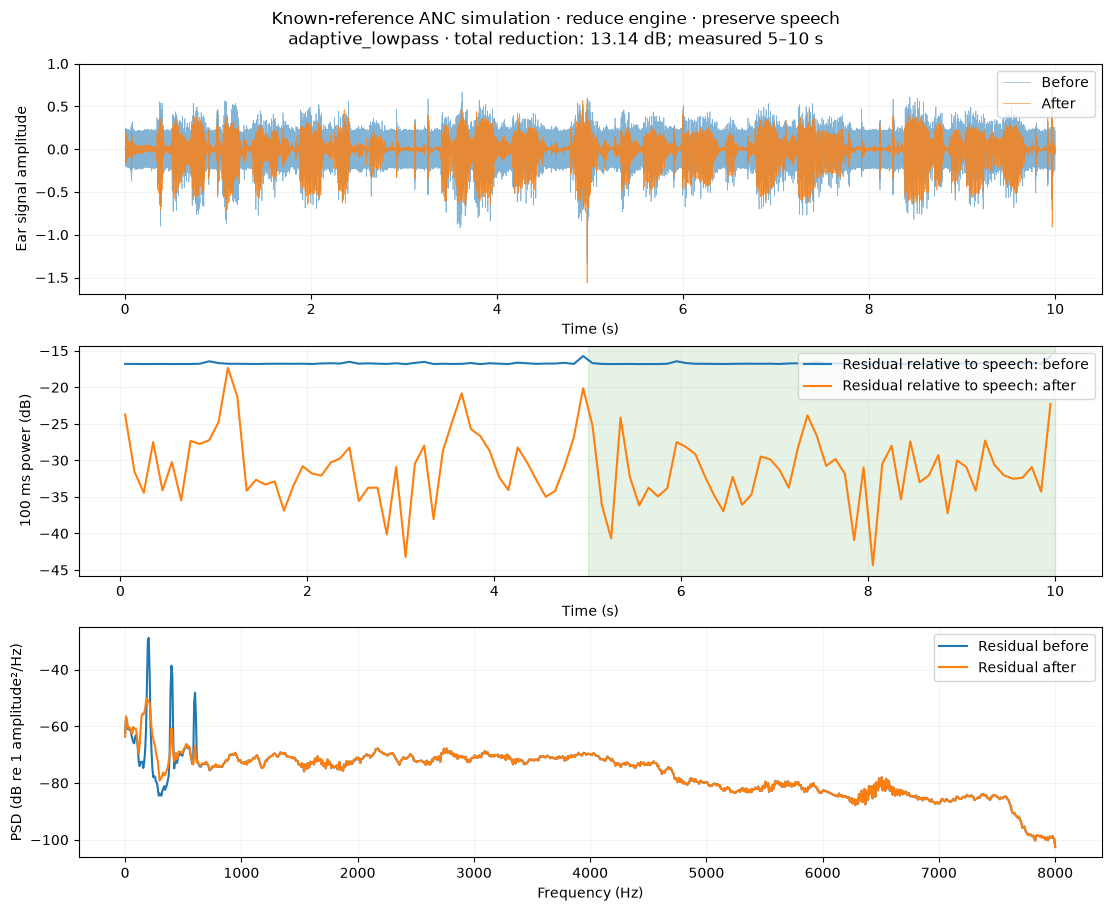

Saved audio and full metrics in C:\Users\arcab\Documents\Codex\2026-10-10\quantasound-combines-ai-and-quantum-optimization\outputs\QuantaSound\demo2\local\notebook_audible_hum
{
  "engine": {
    "file": null,
    "repeated_to_length": false,
    "rms_after_scaling": 0.16,
    "input_gain": 0.21574395598823745,
    "generator": "Synthetic 200 Hz hum plus 400/600 Hz harmonics; not a real engine recording",
    "scene": "audible_hum"
  },
  "keyboard": {
    "file": "1-137-A-32.wav",
    "repeated_to_length": true,
    "rms_after_scaling": 0.025,
    "input_gain": 2.247917804045564,
    "scene": "audible_hum"
  },
  "speech": {
    "file": "libri1.ogg",
    "repeated_to_length": false,
    "rms_after_scaling": 0.12,
    "input_gain": 1.0446185609930014,
    "scene": "audible_hum"
  }
}


In [2]:
from demo2.presentation import show_sources
audible_sources, audible_provenance = load_sources(scene='audible_hum')
show_sources(audible_sources)
audible_result = simulate(audible_sources, ['engine'])
audible_result.metrics['scene'] = 'audible_hum'
show_result(audible_result, root/'demo2'/'local'/'notebook_audible_hum')
print(json.dumps(audible_provenance, indent=2))

## 1 · Your sound preferences
Select engine and/or keyboard to reduce; speech is always designated for preservation. Leave both unchecked to hear the no-cancellation baseline. Click **Run cancellation** to compute the result. Click **Save preferences** to store a named profile. The saved-profile dropdown selects a name; click **Load profile** to apply it. A profile named `default` is restored when the controls reopen.

Profiles are plain local JSON under `demo2/local/profiles/`, excluded from Git. They store deliberate choices; no preference learning is claimed. The current result goes to `demo2/local/latest/`, replacing the previous local run.

In [3]:
from demo2.ui import show_controls
controls = show_controls()

## 2 · Reproducible example: reduce engine, preserve speech and keyboard
The following cells run independently of the controls so the notebook has reviewable saved outputs. We repeat the five-second environmental recordings to ten seconds. Speech uses its first ten seconds. All tracks are resampled to 16 kHz, centered and scaled to documented RMS levels; repeated material is an easier stationary teaching case.

Assumptions: one shared primary FIR with 32-sample delay, a known secondary FIR with a low-pass speaker model (1.5 kHz cutoff), 64 controller taps and μ=0.004. The reference arrives early enough for a causal controller. An independent ear disturbance sets a finite noise floor. There is no actuator clipping or changing acoustic path.

Online FxLMS, low-pass secondary path
Paired adaptive reruns


Measurement,Result,Meaning
Total residual-noise reduction,3.73 dB,Higher is better; unselected noise is still present
Selected-target residual reduction,12.45 dB,Includes added artifacts; can be negative
Speech-reference SDR before → after,-2.55 → 1.18 dB,Remaining interference and distortion relative to clean speech
Speech counterfactual distortion,15.55% RMS,Lower is better; paired speech-present/absent runs
Speech counterfactual gain,1.0024,Near 1 is desirable; not a perceptual speech-quality score


Before — same playback gain as after


After — do not adjust player volume between comparisons


Quick A/B: BEFORE (final 5 s), 0.5 s silence, AFTER (same final 5 s). One player, unchanged gain.


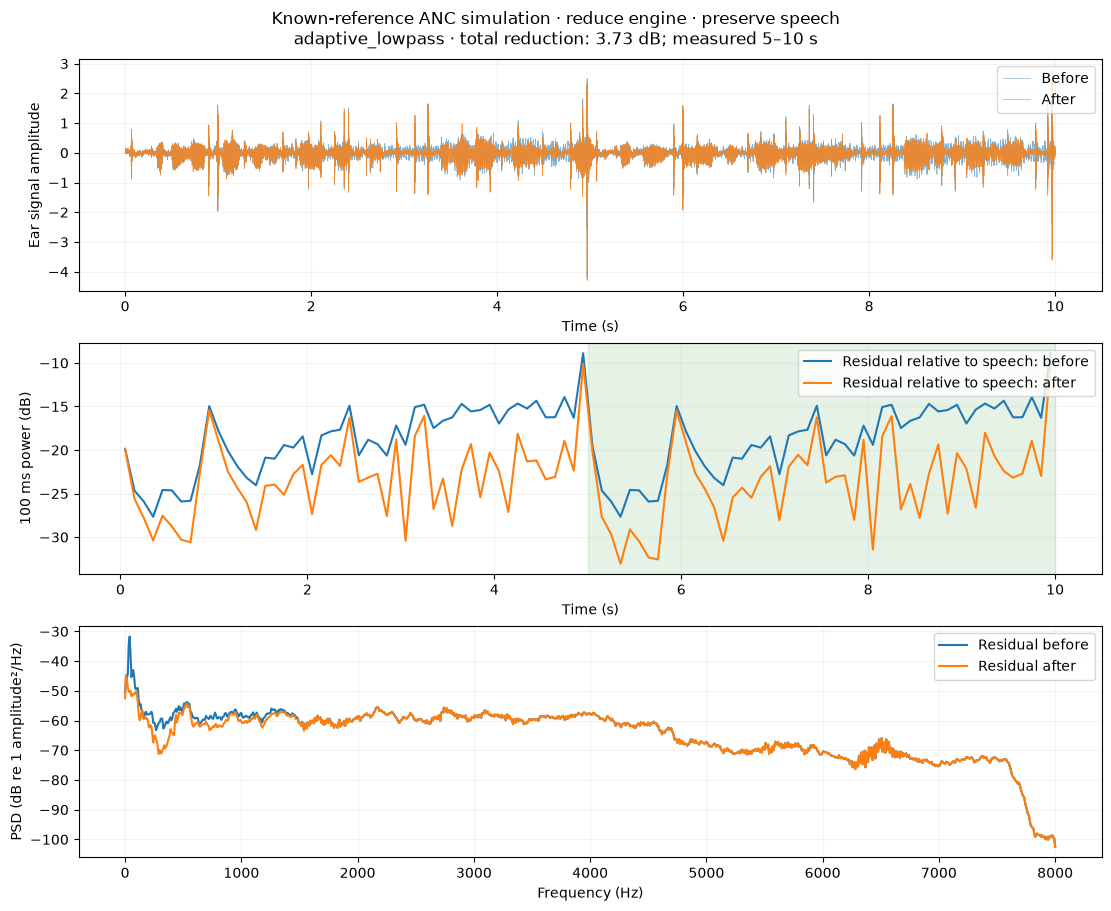

Saved audio and full metrics in C:\Users\arcab\Documents\Codex\2026-10-10\quantasound-combines-ai-and-quantum-optimization\outputs\QuantaSound\demo2\local\notebook_engine
{
  "engine": {
    "file": "1-18527-A-44.wav",
    "repeated_to_length": true,
    "rms_after_scaling": 0.12,
    "input_gain": 1.5846252380499708,
    "scene": "recorded"
  },
  "keyboard": {
    "file": "1-137-A-32.wav",
    "repeated_to_length": true,
    "rms_after_scaling": 0.1,
    "input_gain": 8.991671216182256,
    "scene": "recorded"
  },
  "speech": {
    "file": "libri1.ogg",
    "repeated_to_length": false,
    "rms_after_scaling": 0.12,
    "input_gain": 1.0446185609930014,
    "scene": "recorded"
  }
}


In [4]:
sources, provenance = load_sources()
engine_result = simulate(sources, ['engine'])
show_result(engine_result, root/'demo2'/'local'/'notebook_engine')
print(json.dumps(provenance, indent=2))

## 3 · Keyboard: original setup gives weak reduction, not removal
The original result below is a **limitation case**: about 2.49 dB selected-target residual reduction. Keyboard impacts span a broad frequency range, and this 1.5 kHz low-pass speaker model cannot reproduce much of the required anti-noise. The clicks remain audible. See the explicitly different calibrated-model comparisons immediately below; do not present this original case as successful keyboard removal.

Online FxLMS, low-pass secondary path
Paired adaptive reruns


Measurement,Result,Meaning
Total residual-noise reduction,0.89 dB,Higher is better; unselected noise is still present
Selected-target residual reduction,2.49 dB,Includes added artifacts; can be negative
Speech-reference SDR before → after,-2.55 → -1.66 dB,Remaining interference and distortion relative to clean speech
Speech counterfactual distortion,4.55% RMS,Lower is better; paired speech-present/absent runs
Speech counterfactual gain,1.0013,Near 1 is desirable; not a perceptual speech-quality score


Before — same playback gain as after


After — do not adjust player volume between comparisons


Quick A/B: BEFORE (final 5 s), 0.5 s silence, AFTER (same final 5 s). One player, unchanged gain.


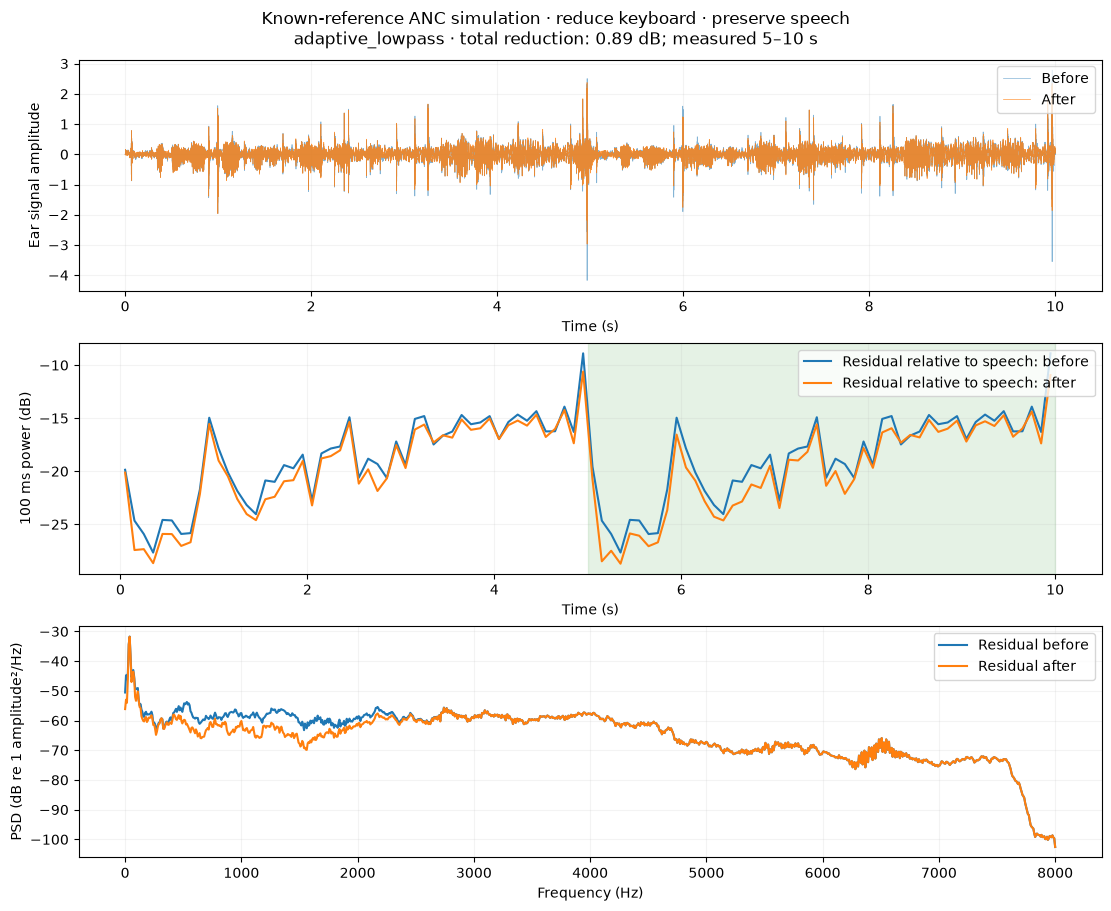

Saved audio and full metrics in C:\Users\arcab\Documents\Codex\2026-10-10\quantasound-combines-ai-and-quantum-optimization\outputs\QuantaSound\demo2\local\notebook_keyboard


In [5]:
keyboard_result = simulate(sources, ['keyboard'])
show_result(keyboard_result, root/'demo2'/'local'/'notebook_keyboard')

### Keyboard comparison: calibration versus speaker bandwidth
We fit a fixed 64-tap control FIR so `S*W ≈ P` with an effort penalty of 0.001. Calibration uses the known paths only, **not the evaluation recording**. At playback, the isolated keyboard reference passes through W and then S to produce anti-noise; this is not direct subtraction of keyboard samples from the output.

First keep the **same low-pass speaker**: about 4.69 dB target reduction, still incomplete, with a large required control peak. Next use a **DIFFERENT ideal broadband speaker path** `[0, 0, 0.7, 0.2, −0.05]`: about 38.91 dB target reduction. The second result is an ideal feasibility illustration, not improved performance on the original speaker model. Both have exact, early, separately known noise references and omit actuator clipping; controller output peaks are reported in arbitrary simulation units.

The fixed controller does not adapt to speech, so zero speech counterfactual error is **by construction**, not an independently demonstrated speech-separation achievement. The engine remains because only the keyboard is selected.

MODEL: calibrated_lowpass
Offline calibrated fixed FIR; same low-pass path
Zero speech adaptation error is by construction: frozen controller and exact isolated noise reference


Measurement,Result,Meaning
Total residual-noise reduction,1.29 dB,Higher is better; unselected noise is still present
Selected-target residual reduction,4.69 dB,Includes added artifacts; can be negative
Speech-reference SDR before → after,-2.55 → -1.26 dB,Remaining interference and distortion relative to clean speech
Speech counterfactual distortion,0.00% RMS,Lower is better; paired speech-present/absent runs
Speech counterfactual gain,1.0000,Near 1 is desirable; not a perceptual speech-quality score


Before — same playback gain as after


After — do not adjust player volume between comparisons


Quick A/B: BEFORE (final 5 s), 0.5 s silence, AFTER (same final 5 s). One player, unchanged gain.


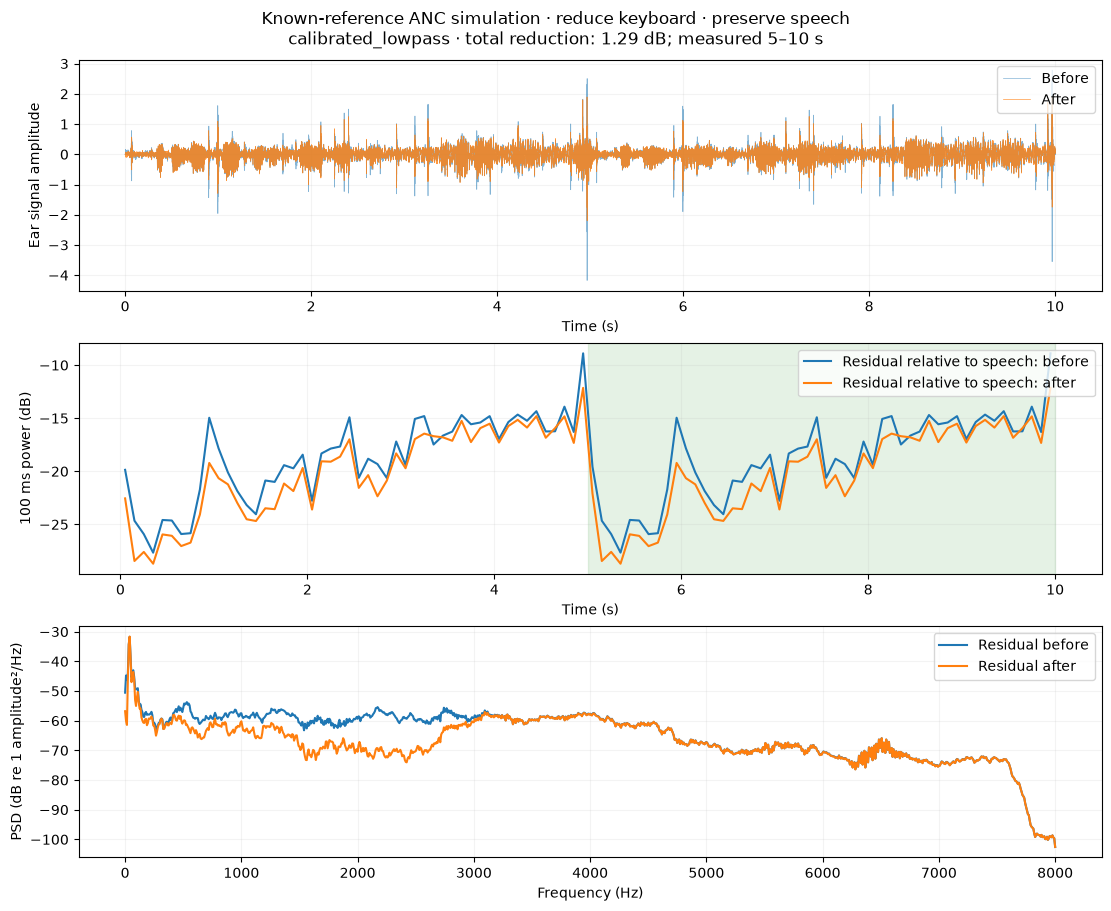

Saved audio and full metrics in C:\Users\arcab\Documents\Codex\2026-10-10\quantasound-combines-ai-and-quantum-optimization\outputs\QuantaSound\demo2\local\calibrated_lowpass
Control RMS / peak: 0.5429452404339434 21.384902059437895
MODEL: calibrated_broadband
Offline calibrated fixed FIR; DIFFERENT ideal broadband secondary path; not original hardware
Zero speech adaptation error is by construction: frozen controller and exact isolated noise reference


Measurement,Result,Meaning
Total residual-noise reduction,2.18 dB,Higher is better; unselected noise is still present
Selected-target residual reduction,38.91 dB,Includes added artifacts; can be negative
Speech-reference SDR before → after,-2.55 → -0.37 dB,Remaining interference and distortion relative to clean speech
Speech counterfactual distortion,0.00% RMS,Lower is better; paired speech-present/absent runs
Speech counterfactual gain,1.0000,Near 1 is desirable; not a perceptual speech-quality score


Before — same playback gain as after


After — do not adjust player volume between comparisons


Quick A/B: BEFORE (final 5 s), 0.5 s silence, AFTER (same final 5 s). One player, unchanged gain.


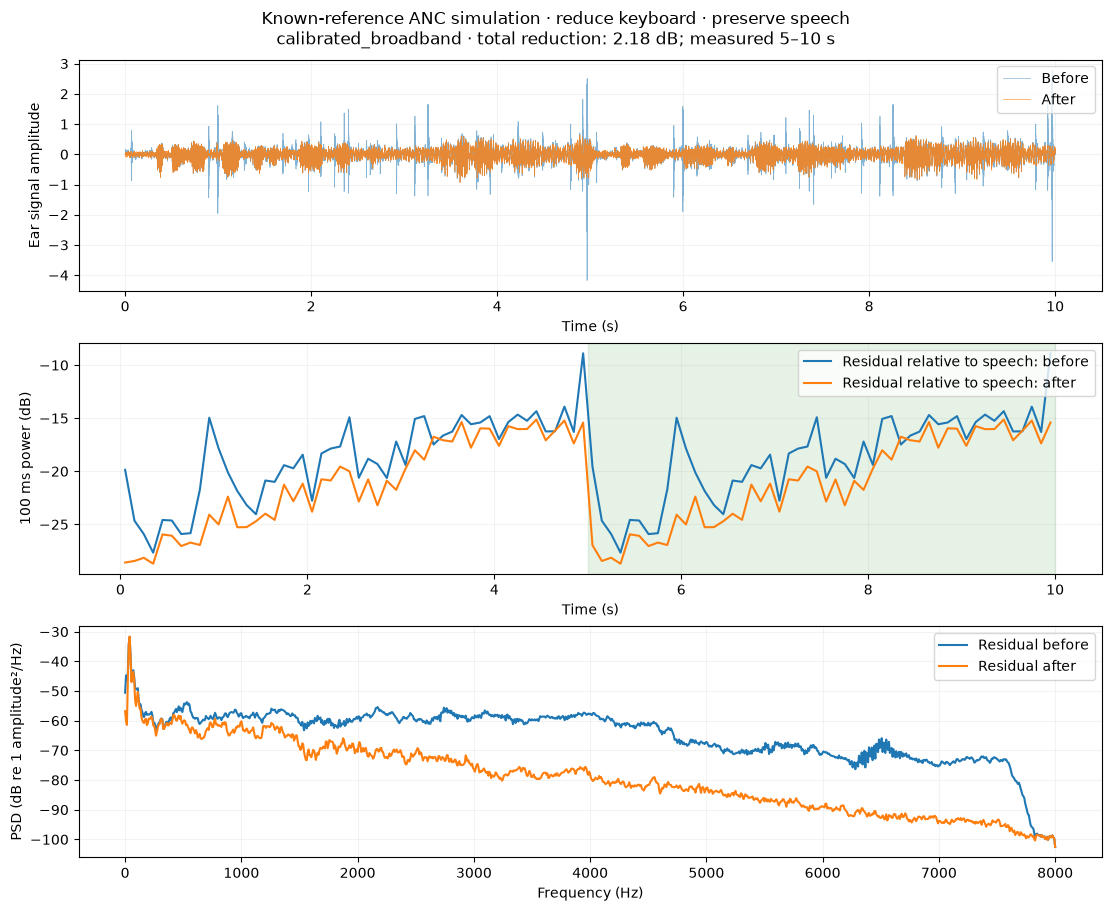

Saved audio and full metrics in C:\Users\arcab\Documents\Codex\2026-10-10\quantasound-combines-ai-and-quantum-optimization\outputs\QuantaSound\demo2\local\calibrated_broadband
Control RMS / peak: 0.10877057249906277 4.957815271524759


In [6]:
for model in ('calibrated_lowpass', 'calibrated_broadband'):
    print('MODEL:', model)
    comparison = simulate(sources, ['keyboard'], controller=model)
    show_result(comparison, root/'demo2'/'local'/model)
    print('Control RMS / peak:', comparison.metrics['control_rms'], comparison.metrics['control_peak'])

## 4 · Reading the measurements
- **Total residual-noise reduction:** 10 log₁₀(power(before − clean speech) / power(after − clean speech)). This includes unselected noise and any controller artifacts; it need not be large when preserving another noisy source.
- **Selected-target residual reduction:** compare selected-source-plus-floor power with `after − wanted`. Wanted includes speech and unselected sounds. This is a reference-based residual metric, not an isolated-source measurement from a real microphone.
- **Speech-reference SDR:** speech power divided by error power relative to clean speech; includes remaining interference. No delay or gain fitting is used.
- **Speech counterfactual distortion:** repeat adaptation with speech absent, holding reference, noise floor and paths fixed. Subtract that output from the speech-present output. Compare the difference with clean speech at the ear; report error RMS as a percentage of speech RMS. This captures speech-driven adaptation effects, but is not a perceptual intelligibility score or a source-separation result.
- **Speech counterfactual gain:** projection of that difference onto clean speech; near 1 is desirable. Read it alongside distortion, not alone.

Metrics use the final five seconds; whole-run noise reduction is also saved. All outputs are simulated amplitudes, not calibrated sound-pressure levels. Both listening files use the same gain. Keep player/system volume unchanged between before and after.

## 5 · Save and reload preferences in Python
The interface uses these same functions. This isolated temporary-directory example demonstrates persistence without overwriting your real saved profiles.

In [7]:
import tempfile
from demo2.profiles import save_profile, load_profile
with tempfile.TemporaryDirectory() as example_directory:
    saved = save_profile('student', ['keyboard'], example_directory)
    restored = load_profile('student', example_directory)
    assert restored == saved
    print('Reloaded from disk:', restored)

Reloaded from disk: {'version': 1, 'name': 'student', 'reduce': ['keyboard'], 'preserve_speech': True}


## 6 · Qiskit offline research module
Qiskit executes a four-qubit p=1 QAOA circuit using its statevector simulator. We cross-check its output probabilities against the existing NumPy implementation and compare against exhaustive classical search. SciPy optimizes the circuit angles; no IBM account, quantum device or cloud service is required.

This separate toy QUBO has an artificial exactly-two soft budget and four sound choices. Its results **do not override the sound-selection controls or drive FxLMS**. It is not yet a physically calibrated acoustic optimizer. scikit-learn continues to implement the five-class MFCC/random-forest classifier in `demo1/classifier.py`; classification is separate from obtaining cancellation waveforms.

{
  "status": "PRELIMINARY: toy offline simulation; no quantum advantage claim",
  "backend": "qiskit",
  "angles": [
    0.22168023904571932,
    -0.4849924116495048
  ],
  "sources": [
    "engine",
    "typing",
    "speech",
    "siren"
  ],
  "exact_bits": [
    1,
    1,
    0,
    0
  ],
  "exact_cost": -3.4000000000000004,
  "qaoa_expected_cost": 0.8480864721536951,
  "qaoa_expected_gap": 4.2480864721536955,
  "optimal_probability": 0.26987011719672777,
  "most_likely_bits": [
    1,
    1,
    0,
    0
  ],
  "optimizer_success": true,
  "objective_evaluations": 265,
  "exact_argmin_seconds": 1.880000127130188e-05,
  "qaoa_optimization_seconds": 0.6535408999989158,
  "timing_scope": "Shared cost table excluded; timings are illustrative, not a scaling study"
}
     ┌───┐»
q_0: ┤ H ├»
     ├───┤»
q_1: ┤ H ├»
     ├───┤»
q_2: ┤ H ├»
     ├───┤»
q_3: ┤ H ├»
     └───┘»
«     ┌──────────────────────────────────────────────────────────────────────────────────────────────────────────

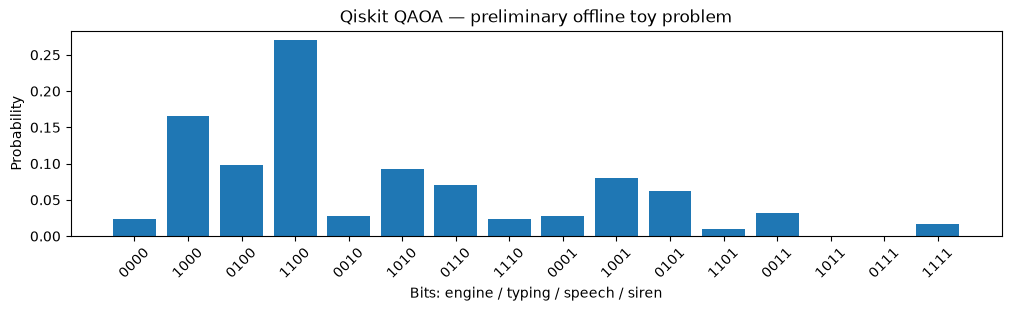

In [8]:
from demo1.quantum import benchmark, problem, statevector, qiskit_statevector, qiskit_circuit
_, costs = problem()
angles = [.3, .7]
np.testing.assert_allclose(np.abs(statevector(angles, costs))**2,
                           np.abs(qiskit_statevector(angles, costs))**2, atol=1e-12)
states, costs, probabilities, qiskit_metrics = benchmark(backend='qiskit')
print(json.dumps(qiskit_metrics, indent=2))
print(qiskit_circuit(qiskit_metrics['angles'], costs).draw(output='text'))
fig, ax = plt.subplots(figsize=(10, 3), layout='constrained')
ax.bar(range(16), probabilities)
ax.set_xticks(range(16), [''.join(str(int(v)) for v in row) for row in states], rotation=45)
ax.set(xlabel='Bits: engine / typing / speech / siren', ylabel='Probability', title='Qiskit QAOA — preliminary offline toy problem')
plt.show()

## What this milestone proves
The user's saved choices now affect a connected ANC simulation with real-source mixtures, generated anti-noise, listening outputs and quantitative evaluation. It does not yet prove microphone-only source separation, live low-latency cancellation, learned preferences or quantum advantage.

Run `python -m demo2.run` to export all four selections to `demo2/results/`; `python -m pytest -q` checks DSP, profile storage, widget callbacks and Qiskit/NumPy agreement. Source attribution is in `../demo1/DATA_SOURCES.md`, with the ten-second speech excerpt/repeated environmental clips documented in `README.md` here.

References: [Qiskit Statevector](https://docs.quantum.ibm.com/api/qiskit/2.0/qiskit.quantum_info.Statevector), [QAOA paper](https://arxiv.org/abs/1411.4028), [ESC-50](https://github.com/karolpiczak/ESC-50).